NOTEBOOK 09 — HYBRID MODEL DEVELOPMENT

Configuration:
Random State: 42
Test Size: 0.2
Cross-Validation Folds: 5
Output Directory: hybrid_model_results

DATASET LOADED
Dataset Shape: (10000, 45)

DATA VALIDATION

Missing Values: 0
Duplicate Rows: 0

Target Distribution:
churn
0    8979
1    1021
Name: count, dtype: int64

Target Distribution (%):
churn
0    89.79
1    10.21
Name: proportion, dtype: float64

FEATURES AND TARGET
Feature Shape: (10000, 44)
Target Shape: (10000,)

TRAIN / TEST SPLIT

Training Shape: (8000, 44)
Testing Shape: (2000, 44)

Training Target Distribution:
churn
0    7183
1     817
Name: count, dtype: int64

Testing Target Distribution:
churn
0    1796
1     204
Name: count, dtype: int64

FEATURE TYPES

Categorical Variables: 11
['gender', 'country', 'city', 'customer_segment', 'signup_channel', 'contract_type', 'payment_method', 'discount_applied', 'price_increase_last_3m', 'complaint_type', 'survey_response']

Numerical Variables: 33
['age', 'tenure_months', 'm

,Alpha,Logistic_Weight,XGBoost_Weight,ROC_AUC,Average_Precision,F1,Recall,Precision,Balanced_Accuracy
1,0.1,0.1,0.9,0.8025,0.2922,0.1197,0.0697,0.4245,0.5295
2,0.2,0.2,0.8,0.8016,0.2938,0.1659,0.1040,0.4148,0.5438
0,0.0,0.0,1.0,0.8011,0.2907,0.0752,0.0416,0.3961,0.5173
3,0.3,0.3,0.7,0.7981,0.2934,0.2126,0.1469,0.3858,0.5602
4,0.4,0.4,0.6,0.7928,0.2901,0.2579,0.2032,0.3537,0.5806
5,0.5,0.5,0.5,0.7863,0.2873,0.2895,0.2717,0.3102,0.6015
6,0.6,0.6,0.4,0.7793,0.2828,0.3316,0.3758,0.2976,0.6373
7,0.7,0.7,0.3,0.7717,0.2765,0.3415,0.4602,0.2717,0.6598
8,0.8,0.8,0.2,0.7640,0.2703,0.3486,0.5569,0.2538,0.6852
9,0.9,0.9,0.1,0.7561,0.2641,0.3411,0.6389,0.2327,0.6994



BEST HYBRID CONFIGURATION
Logistic Regression Weight: 0.1
XGBoost Weight: 0.9
CV ROC-AUC: 0.8025
CV Average Precision: 0.2922
CV F1: 0.1197
CV Recall: 0.0697

Evaluating Logistic Regression...

Evaluating XGBoost...

FINAL CROSS-VALIDATION COMPARISON


,Model,ROC_AUC,Average_Precision,F1,Recall,Precision,Balanced_Accuracy
0,Logistic Regression,0.7485,0.2565,0.3112,0.6842,0.2014,0.6877
1,XGBoost,0.8011,0.2907,0.0752,0.0416,0.3961,0.5173
2,Hybrid,0.8025,0.2922,0.1197,0.0697,0.4245,0.5295


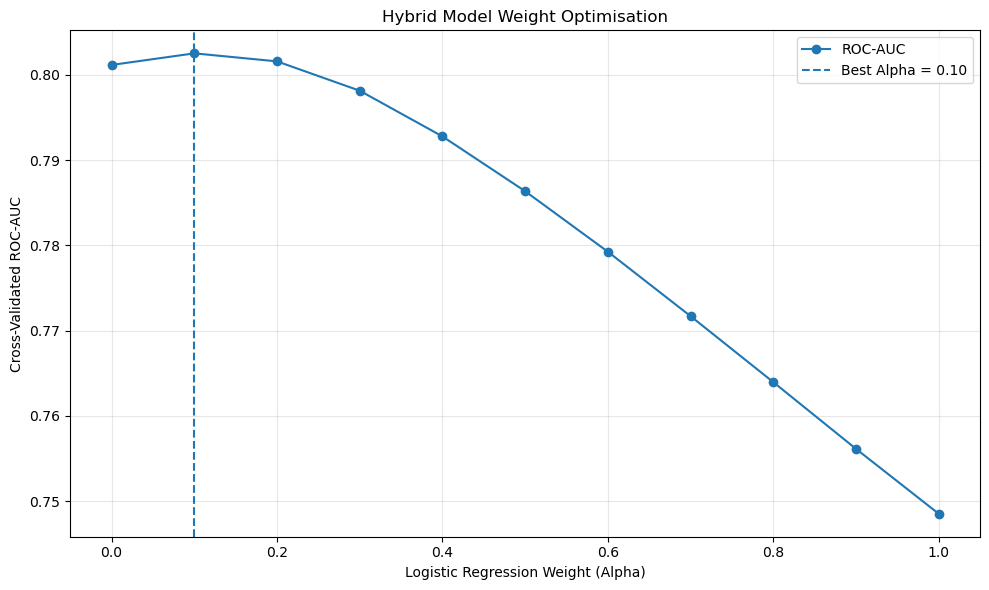

Threshold optimisation Fold 1/5...
Threshold optimisation Fold 2/5...
Threshold optimisation Fold 3/5...
Threshold optimisation Fold 4/5...
Threshold optimisation Fold 5/5...

OPTIMAL HYBRID THRESHOLD
Selected Threshold: 0.17

Cross-Validated Performance:


Threshold            0.1700
Precision            0.2490
Recall               0.8225
F1                   0.3823
Balanced_Accuracy    0.7702
Name: 7, dtype: float64

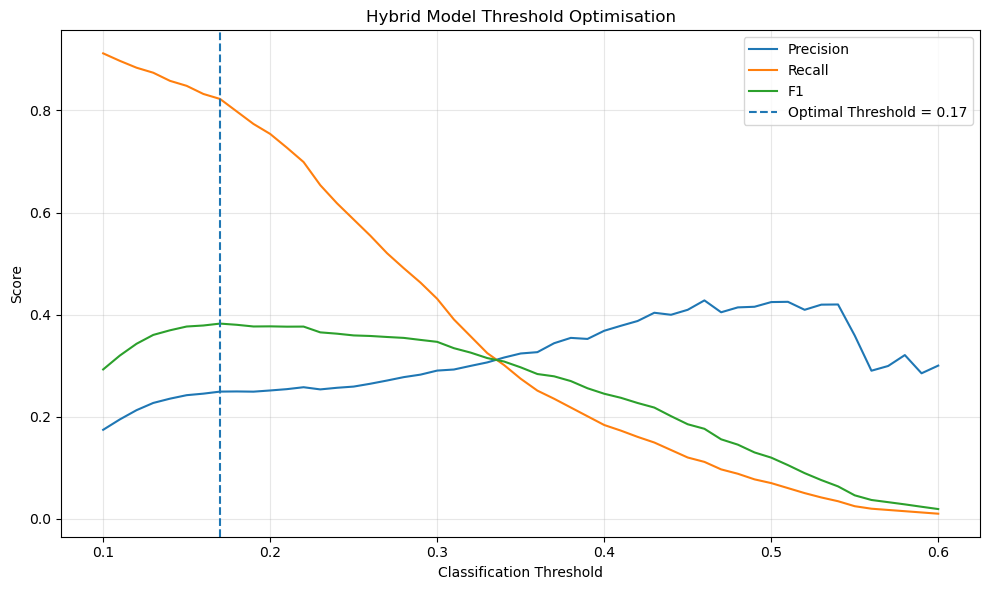


TRAINING FINAL INDIVIDUAL MODELS
Training Logistic Regression...
Training XGBoost...
Final individual models trained successfully.

FINAL TEST PROBABILITIES
Logistic Regression probabilities generated.
XGBoost probabilities generated.
Hybrid probabilities generated.

FINAL TEST SET MODEL COMPARISON


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Balanced_Accuracy,Specificity
0,Logistic Regression,0.50,0.6900,0.1959,0.6569,0.3018,0.7416,0.2696,0.6753,0.6938
1,XGBoost,0.50,0.8965,0.4211,0.0392,0.0717,0.7959,0.3048,0.5165,0.9939
2,Hybrid,0.17,0.7175,0.2440,0.8431,0.3784,0.7962,0.3111,0.7732,0.7032



HYBRID CONFUSION MATRIX
[[1263  533]
 [  32  172]]


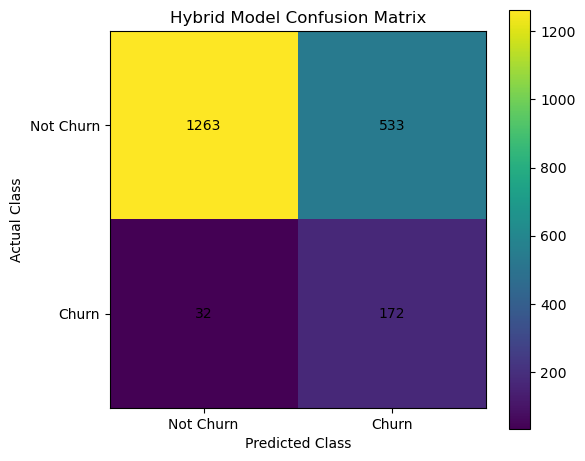


HYBRID CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Not Churn       0.98      0.70      0.82      1796
       Churn       0.24      0.84      0.38       204

    accuracy                           0.72      2000
   macro avg       0.61      0.77      0.60      2000
weighted avg       0.90      0.72      0.77      2000


NOTEBOOK 09 — HYBRID MODEL DEVELOPMENT COMPLETED

Hybrid Architecture:
Logistic Regression + XGBoost

Logistic Regression Weight: 0.1
XGBoost Weight: 0.9

Hybrid CV ROC-AUC: 0.8025
Hybrid CV F1: 0.1197
Hybrid CV Recall: 0.0697

Hybrid Optimal Threshold: 0.17

Final Test Results:


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Balanced_Accuracy,Specificity
0,Logistic Regression,0.50,0.6900,0.1959,0.6569,0.3018,0.7416,0.2696,0.6753,0.6938
1,XGBoost,0.50,0.8965,0.4211,0.0392,0.0717,0.7959,0.3048,0.5165,0.9939
2,Hybrid,0.17,0.7175,0.2440,0.8431,0.3784,0.7962,0.3111,0.7732,0.7032



Output Directory:
hybrid_model_results

END OF NOTEBOOK 09


In [ ]:


# Libraries

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

from imblearn.pipeline import Pipeline as ImbPipeline

from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier


# Configuration 

RANDOM_STATE = 42

TEST_SIZE = 0.20

N_SPLITS = 5

OUTPUT_DIR = "hybrid_model_results"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


print("=" * 70)
print("NOTEBOOK 09 — HYBRID MODEL DEVELOPMENT")
print("=" * 70)

print("\nConfiguration:")
print("Random State:", RANDOM_STATE)
print("Test Size:", TEST_SIZE)
print("Cross-Validation Folds:", N_SPLITS)
print("Output Directory:", OUTPUT_DIR)



# Load Feature engineered dataset

DATA_PATH = "customer_churn_feature_engineered.csv"

df = pd.read_csv(
    DATA_PATH
)


print("\n" + "=" * 70)
print("DATASET LOADED")
print("=" * 70)

print(
    "Dataset Shape:",
    df.shape
)


# Data Validation 
print("\n" + "=" * 70)
print("DATA VALIDATION")
print("=" * 70)

print(
    "\nMissing Values:",
    df.isnull().sum().sum()
)

print(
    "Duplicate Rows:",
    df.duplicated().sum()
)

print(
    "\nTarget Distribution:"
)

print(
    df["churn"].value_counts()
)

print(
    "\nTarget Distribution (%):"
)

print(
    (
        df["churn"]
        .value_counts(normalize=True)
        * 100
    ).round(2)
)


# Features and Target 
X = df.drop(
    columns=["churn"]
)

y = df["churn"]


print("\n" + "=" * 70)
print("FEATURES AND TARGET")
print("=" * 70)

print(
    "Feature Shape:",
    X.shape
)

print(
    "Target Shape:",
    y.shape
)


# TRAIN / TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=TEST_SIZE,

    stratify=y,

    random_state=RANDOM_STATE
)


print("\n" + "=" * 70)
print("TRAIN / TEST SPLIT")
print("=" * 70)

print(
    "\nTraining Shape:",
    X_train.shape
)

print(
    "Testing Shape:",
    X_test.shape
)

print(
    "\nTraining Target Distribution:"
)

print(
    y_train.value_counts()
)

print(
    "\nTesting Target Distribution:"
)

print(
    y_test.value_counts()
)


# Identify Feature Types
categorical_features = X_train.select_dtypes(
    include=[
        "object",
        "string",
        "category"
    ]
).columns.tolist()


numerical_features = X_train.select_dtypes(
    include=[
        "number"
    ]
).columns.tolist()


print("\n" + "=" * 70)
print("FEATURE TYPES")
print("=" * 70)

print(
    "\nCategorical Variables:",
    len(categorical_features)
)

print(
    categorical_features
)

print(
    "\nNumerical Variables:",
    len(numerical_features)
)

print(
    numerical_features
)


# Leakage safe preprocessing 
numeric_pipeline = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",

            StandardScaler()
        )
    ]
)


categorical_pipeline = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="most_frequent"
            )
        ),

        (
            "encoder",

            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )
    ]
)


preprocessor = ColumnTransformer(

    transformers=[

        (
            "numerical",

            numeric_pipeline,

            numerical_features
        ),

        (
            "categorical",

            categorical_pipeline,

            categorical_features
        )
    ]
)


print("\n" + "=" * 70)
print("PREPROCESSING")
print("=" * 70)

print(
    "Leakage-safe preprocessing pipeline created."
)


# Stratified Cross Validation 
cv = StratifiedKFold(

    n_splits=N_SPLITS,

    shuffle=True,

    random_state=RANDOM_STATE
)


print("\n" + "=" * 70)
print("CROSS-VALIDATION")
print("=" * 70)

print(
    "Method: Stratified 5-Fold Cross-Validation"
)

print(
    "Random State:",
    RANDOM_STATE
)


# Optimised logistic regression
logistic_regression = LogisticRegression(

    C=0.001,

    solver="liblinear",

    max_iter=2000,

    random_state=RANDOM_STATE
)


# Optimised XGBOOST

xgboost = XGBClassifier(

    n_estimators=200,

    max_depth=3,

    learning_rate=0.05,

    subsample=0.8,

    colsample_bytree=0.8,

    min_child_weight=1,

    random_state=RANDOM_STATE,

    eval_metric="logloss",

    n_jobs=-1
)



# logistic regression pipeline
logistic_pipeline = ImbPipeline(

    steps=[

        (
            "preprocessing",

            preprocessor
        ),

        (
            "smote",

            SMOTE(
                random_state=RANDOM_STATE
            )
        ),

        (
            "model",

            logistic_regression
        )
    ]
)


# XGBOOST PIPELINE

xgb_pipeline = ImbPipeline(

    steps=[

        (
            "preprocessing",

            preprocessor
        ),

        (
            "smote",

            SMOTE(
                random_state=RANDOM_STATE
            )
        ),

        (
            "model",

            xgboost
        )
    ]
)


print("\n" + "=" * 70)
print("INDIVIDUAL MODEL PIPELINES")
print("=" * 70)

print(
    "Logistic Regression pipeline created."
)

print(
    "XGBoost pipeline created."
)

print(
    "SMOTE is applied inside each training fold."
)


# HYBRID MODEL DEFINITION

print("\n" + "=" * 70)
print("HYBRID MODEL ARCHITECTURE")
print("=" * 70)

print("""
The hybrid model combines:

Logistic Regression
    ↓
Interpretable linear component

XGBoost
    ↓
Nonlinear predictive component

Hybrid Probability:

P(Hybrid) =
    Alpha × P(Logistic Regression)
    +
    (1 - Alpha) × P(XGBoost)

Alpha = Logistic Regression contribution.
""")


# HYBRID WEIGHT SEARCH

hybrid_weights = np.arange(
    0.0,
    1.01,
    0.10
)


print(
    "Candidate Logistic Regression weights:"
)

print(
    hybrid_weights
)


# CROSS-VALIDATED HYBRID EVALUATION

hybrid_cv_results = []


for fold, (train_idx, val_idx) in enumerate(

    cv.split(
        X_train,
        y_train
    ),

    start=1
):

    print(
        f"\nProcessing Fold {fold}/{N_SPLITS}..."
    )


    X_cv_train = X_train.iloc[
        train_idx
    ]

    X_cv_val = X_train.iloc[
        val_idx
    ]

    y_cv_train = y_train.iloc[
        train_idx
    ]

    y_cv_val = y_train.iloc[
        val_idx
    ]


    # --------------------------------------------------------
    # Clone pipelines
    # --------------------------------------------------------

    lr_model = clone(
        logistic_pipeline
    )

    xgb_model = clone(
        xgb_pipeline
    )


    # --------------------------------------------------------
    # Train models
    # --------------------------------------------------------

    lr_model.fit(
        X_cv_train,
        y_cv_train
    )

    xgb_model.fit(
        X_cv_train,
        y_cv_train
    )


    # --------------------------------------------------------
    # Validation probabilities
    # --------------------------------------------------------

    lr_probabilities = (

        lr_model
        .predict_proba(
            X_cv_val
        )[:, 1]
    )


    xgb_probabilities = (

        xgb_model
        .predict_proba(
            X_cv_val
        )[:, 1]
    )


    # --------------------------------------------------------
    # Evaluate hybrid weights
    # --------------------------------------------------------

    for alpha in hybrid_weights:

        hybrid_probabilities = (

            alpha
            * lr_probabilities

            +

            (1 - alpha)
            * xgb_probabilities
        )


        hybrid_predictions = (

            hybrid_probabilities >= 0.50

        ).astype(int)


        hybrid_cv_results.append({

            "Fold":
                fold,

            "Alpha":
                alpha,

            "Logistic_Weight":
                alpha,

            "XGBoost_Weight":
                1 - alpha,

            "ROC_AUC":
                roc_auc_score(
                    y_cv_val,
                    hybrid_probabilities
                ),

            "Average_Precision":
                average_precision_score(
                    y_cv_val,
                    hybrid_probabilities
                ),

            "F1":
                f1_score(
                    y_cv_val,
                    hybrid_predictions,
                    zero_division=0
                ),

            "Recall":
                recall_score(
                    y_cv_val,
                    hybrid_predictions,
                    zero_division=0
                ),

            "Precision":
                precision_score(
                    y_cv_val,
                    hybrid_predictions,
                    zero_division=0
                ),

            "Balanced_Accuracy":
                balanced_accuracy_score(
                    y_cv_val,
                    hybrid_predictions
                )
        })


hybrid_cv_results_df = pd.DataFrame(
    hybrid_cv_results
)


print(
    "\nCross-validated hybrid evaluation completed."
)



# HYBRID CV SUMMARY

hybrid_summary = (

    hybrid_cv_results_df

    .groupby("Alpha")

    [
        [
            "Logistic_Weight",
            "XGBoost_Weight",
            "ROC_AUC",
            "Average_Precision",
            "F1",
            "Recall",
            "Precision",
            "Balanced_Accuracy"
        ]
    ]

    .mean()

    .reset_index()
)


hybrid_summary = hybrid_summary.sort_values(

    by="ROC_AUC",

    ascending=False
)


print("\n" + "=" * 70)
print("HYBRID CROSS-VALIDATION RESULTS")
print("=" * 70)

display(
    hybrid_summary.round(4)
)


# SELECT BEST HYBRID WEIGHT

best_hybrid_row = hybrid_summary.iloc[0]


best_alpha = (
    best_hybrid_row["Alpha"]
)

best_logistic_weight = (
    best_hybrid_row["Logistic_Weight"]
)

best_xgb_weight = (
    best_hybrid_row["XGBoost_Weight"]
)


print("\n" + "=" * 70)
print("BEST HYBRID CONFIGURATION")
print("=" * 70)

print(
    "Logistic Regression Weight:",
    round(best_logistic_weight, 2)
)

print(
    "XGBoost Weight:",
    round(best_xgb_weight, 2)
)

print(
    "CV ROC-AUC:",
    round(
        best_hybrid_row["ROC_AUC"],
        4
    )
)

print(
    "CV Average Precision:",
    round(
        best_hybrid_row["Average_Precision"],
        4
    )
)

print(
    "CV F1:",
    round(
        best_hybrid_row["F1"],
        4
    )
)

print(
    "CV Recall:",
    round(
        best_hybrid_row["Recall"],
        4
    )
)



# INDIVIDUAL MODEL CROSS-VALIDATION

individual_cv_results = []


for model_name, pipeline in {

    "Logistic Regression":
        logistic_pipeline,

    "XGBoost":
        xgb_pipeline

}.items():

    print(
        f"\nEvaluating {model_name}..."
    )


    fold_results = []


    for train_idx, val_idx in cv.split(

        X_train,
        y_train

    ):

        X_cv_train = X_train.iloc[
            train_idx
        ]

        X_cv_val = X_train.iloc[
            val_idx
        ]

        y_cv_train = y_train.iloc[
            train_idx
        ]

        y_cv_val = y_train.iloc[
            val_idx
        ]


        model = clone(
            pipeline
        )


        model.fit(
            X_cv_train,
            y_cv_train
        )


        probabilities = (

            model
            .predict_proba(
                X_cv_val
            )[:, 1]
        )


        predictions = (

            probabilities >= 0.50

        ).astype(int)


        fold_results.append({

            "ROC_AUC":
                roc_auc_score(
                    y_cv_val,
                    probabilities
                ),

            "Average_Precision":
                average_precision_score(
                    y_cv_val,
                    probabilities
                ),

            "F1":
                f1_score(
                    y_cv_val,
                    predictions,
                    zero_division=0
                ),

            "Recall":
                recall_score(
                    y_cv_val,
                    predictions,
                    zero_division=0
                ),

            "Precision":
                precision_score(
                    y_cv_val,
                    predictions,
                    zero_division=0
                ),

            "Balanced_Accuracy":
                balanced_accuracy_score(
                    y_cv_val,
                    predictions
                )
        })


    fold_results_df = pd.DataFrame(
        fold_results
    )


    individual_cv_results.append({

        "Model":
            model_name,

        "ROC_AUC":
            fold_results_df["ROC_AUC"].mean(),

        "Average_Precision":
            fold_results_df["Average_Precision"].mean(),

        "F1":
            fold_results_df["F1"].mean(),

        "Recall":
            fold_results_df["Recall"].mean(),

        "Precision":
            fold_results_df["Precision"].mean(),

        "Balanced_Accuracy":
            fold_results_df["Balanced_Accuracy"].mean()
    })


individual_cv_df = pd.DataFrame(
    individual_cv_results
)


# FINAL CV COMPARISON

hybrid_comparison = pd.DataFrame({

    "Model": [

        "Logistic Regression",

        "XGBoost",

        "Hybrid"
    ],

    "ROC_AUC": [

        individual_cv_df.loc[
            individual_cv_df["Model"]
            == "Logistic Regression",
            "ROC_AUC"
        ].iloc[0],

        individual_cv_df.loc[
            individual_cv_df["Model"]
            == "XGBoost",
            "ROC_AUC"
        ].iloc[0],

        best_hybrid_row["ROC_AUC"]
    ],

    "Average_Precision": [

        individual_cv_df.loc[
            individual_cv_df["Model"]
            == "Logistic Regression",
            "Average_Precision"
        ].iloc[0],

        individual_cv_df.loc[
            individual_cv_df["Model"]
            == "XGBoost",
            "Average_Precision"
        ].iloc[0],

        best_hybrid_row["Average_Precision"]
    ],

    "F1": [

        individual_cv_df.loc[
            individual_cv_df["Model"]
            == "Logistic Regression",
            "F1"
        ].iloc[0],

        individual_cv_df.loc[
            individual_cv_df["Model"]
            == "XGBoost",
            "F1"
        ].iloc[0],

        best_hybrid_row["F1"]
    ],

    "Recall": [

        individual_cv_df.loc[
            individual_cv_df["Model"]
            == "Logistic Regression",
            "Recall"
        ].iloc[0],

        individual_cv_df.loc[
            individual_cv_df["Model"]
            == "XGBoost",
            "Recall"
        ].iloc[0],

        best_hybrid_row["Recall"]
    ],

    "Precision": [

        individual_cv_df.loc[
            individual_cv_df["Model"]
            == "Logistic Regression",
            "Precision"
        ].iloc[0],

        individual_cv_df.loc[
            individual_cv_df["Model"]
            == "XGBoost",
            "Precision"
        ].iloc[0],

        best_hybrid_row["Precision"]
    ],

    "Balanced_Accuracy": [

        individual_cv_df.loc[
            individual_cv_df["Model"]
            == "Logistic Regression",
            "Balanced_Accuracy"
        ].iloc[0],

        individual_cv_df.loc[
            individual_cv_df["Model"]
            == "XGBoost",
            "Balanced_Accuracy"
        ].iloc[0],

        best_hybrid_row["Balanced_Accuracy"]
    ]
})


print("\n" + "=" * 70)
print("FINAL CROSS-VALIDATION COMPARISON")
print("=" * 70)

display(
    hybrid_comparison.round(4)
)


# HYBRID WEIGHT VISUALISATION

plt.figure(
    figsize=(10, 6)
)

plt.plot(

    hybrid_summary.sort_values("Alpha")["Alpha"],

    hybrid_summary.sort_values("Alpha")["ROC_AUC"],

    marker="o",

    label="ROC-AUC"
)

plt.axvline(

    best_alpha,

    linestyle="--",

    label=(
        f"Best Alpha = "
        f"{best_alpha:.2f}"
    )
)

plt.xlabel(
    "Logistic Regression Weight (Alpha)"
)

plt.ylabel(
    "Cross-Validated ROC-AUC"
)

plt.title(
    "Hybrid Model Weight Optimisation"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(

    os.path.join(
        OUTPUT_DIR,
        "Hybrid_Weight_Optimisation.png"
    ),

    dpi=300
)

plt.show()


# HYBRID THRESHOLD OPTIMISATION

thresholds = np.arange(
    0.10,
    0.61,
    0.01
)


hybrid_threshold_results = []


for fold, (train_idx, val_idx) in enumerate(

    cv.split(
        X_train,
        y_train
    ),

    start=1
):

    print(
        f"Threshold optimisation Fold "
        f"{fold}/{N_SPLITS}..."
    )


    X_cv_train = X_train.iloc[
        train_idx
    ]

    X_cv_val = X_train.iloc[
        val_idx
    ]

    y_cv_train = y_train.iloc[
        train_idx
    ]

    y_cv_val = y_train.iloc[
        val_idx
    ]


    lr_model = clone(
        logistic_pipeline
    )

    xgb_model = clone(
        xgb_pipeline
    )


    lr_model.fit(
        X_cv_train,
        y_cv_train
    )

    xgb_model.fit(
        X_cv_train,
        y_cv_train
    )


    lr_prob = (

        lr_model
        .predict_proba(
            X_cv_val
        )[:, 1]
    )


    xgb_prob = (

        xgb_model
        .predict_proba(
            X_cv_val
        )[:, 1]
    )


    hybrid_prob = (

        best_logistic_weight
        * lr_prob

        +

        best_xgb_weight
        * xgb_prob
    )


    for threshold in thresholds:

        predictions = (

            hybrid_prob >= threshold

        ).astype(int)


        hybrid_threshold_results.append({

            "Fold":
                fold,

            "Threshold":
                threshold,

            "Precision":
                precision_score(
                    y_cv_val,
                    predictions,
                    zero_division=0
                ),

            "Recall":
                recall_score(
                    y_cv_val,
                    predictions,
                    zero_division=0
                ),

            "F1":
                f1_score(
                    y_cv_val,
                    predictions,
                    zero_division=0
                ),

            "Balanced_Accuracy":
                balanced_accuracy_score(
                    y_cv_val,
                    predictions
                )
        })


hybrid_threshold_df = pd.DataFrame(
    hybrid_threshold_results
)


hybrid_threshold_summary = (

    hybrid_threshold_df

    .groupby("Threshold")

    [
        [
            "Precision",
            "Recall",
            "F1",
            "Balanced_Accuracy"
        ]
    ]

    .mean()

    .reset_index()
)



# SELECT HYBRID THRESHOLD

best_hybrid_threshold_row = (

    hybrid_threshold_summary.loc[

        hybrid_threshold_summary["F1"].idxmax()

    ]
)


hybrid_optimal_threshold = (

    best_hybrid_threshold_row[
        "Threshold"
    ]
)


print("\n" + "=" * 70)
print("OPTIMAL HYBRID THRESHOLD")
print("=" * 70)

print(
    "Selected Threshold:",
    round(
        hybrid_optimal_threshold,
        2
    )
)

print(
    "\nCross-Validated Performance:"
)

display(
    best_hybrid_threshold_row.round(4)
)


# HYBRID THRESHOLD PLOT

plt.figure(
    figsize=(10, 6)
)

plt.plot(

    hybrid_threshold_summary["Threshold"],

    hybrid_threshold_summary["Precision"],

    label="Precision"
)

plt.plot(

    hybrid_threshold_summary["Threshold"],

    hybrid_threshold_summary["Recall"],

    label="Recall"
)

plt.plot(

    hybrid_threshold_summary["Threshold"],

    hybrid_threshold_summary["F1"],

    label="F1"
)

plt.axvline(

    hybrid_optimal_threshold,

    linestyle="--",

    label=(
        f"Optimal Threshold = "
        f"{hybrid_optimal_threshold:.2f}"
    )
)

plt.xlabel(
    "Classification Threshold"
)

plt.ylabel(
    "Score"
)

plt.title(
    "Hybrid Model Threshold Optimisation"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(

    os.path.join(
        OUTPUT_DIR,
        "Hybrid_Threshold_Optimisation.png"
    ),

    dpi=300
)

plt.show()



# TRAIN FINAL INDIVIDUAL MODELS

print("\n" + "=" * 70)
print("TRAINING FINAL INDIVIDUAL MODELS")
print("=" * 70)


final_lr_model = clone(
    logistic_pipeline
)

final_xgb_model = clone(
    xgb_pipeline
)


print(
    "Training Logistic Regression..."
)

final_lr_model.fit(
    X_train,
    y_train
)


print(
    "Training XGBoost..."
)

final_xgb_model.fit(
    X_train,
    y_train
)


print(
    "Final individual models trained successfully."
)



# FINAL TEST PROBABILITIES

lr_test_probabilities = (

    final_lr_model
    .predict_proba(
        X_test
    )[:, 1]
)


xgb_test_probabilities = (

    final_xgb_model
    .predict_proba(
        X_test
    )[:, 1]
)



# FINAL HYBRID PROBABILITY

hybrid_test_probabilities = (

    best_logistic_weight
    * lr_test_probabilities

    +

    best_xgb_weight
    * xgb_test_probabilities
)


print("\n" + "=" * 70)
print("FINAL TEST PROBABILITIES")
print("=" * 70)

print(
    "Logistic Regression probabilities generated."
)

print(
    "XGBoost probabilities generated."
)

print(
    "Hybrid probabilities generated."
)



# FINAL TEST PREDICTIONS

lr_test_predictions = (

    lr_test_probabilities >= 0.50

).astype(int)


xgb_test_predictions_default = (

    xgb_test_probabilities >= 0.50

).astype(int)


hybrid_test_predictions_default = (

    hybrid_test_probabilities >= 0.50

).astype(int)


hybrid_test_predictions_optimal = (

    hybrid_test_probabilities
    >= hybrid_optimal_threshold

).astype(int)



# EVALUATION FUNCTION

def evaluate_predictions(

    y_true,

    predictions,

    probabilities,

    threshold

):

    tn, fp, fn, tp = (

        confusion_matrix(
            y_true,
            predictions
        ).ravel()
    )


    specificity = (

        tn / (tn + fp)

        if (tn + fp) > 0

        else 0
    )


    return {

        "Threshold":
            threshold,

        "Accuracy":
            accuracy_score(
                y_true,
                predictions
            ),

        "Precision":
            precision_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "ROC_AUC":
            roc_auc_score(
                y_true,
                probabilities
            ),

        "Average_Precision":
            average_precision_score(
                y_true,
                probabilities
            ),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                y_true,
                predictions
            ),

        "Specificity":
            specificity,

        "TN":
            tn,

        "FP":
            fp,

        "FN":
            fn,

        "TP":
            tp
    }



# FINAL TEST EVALUATION

lr_results = evaluate_predictions(

    y_test,

    lr_test_predictions,

    lr_test_probabilities,

    0.50
)


xgb_results = evaluate_predictions(

    y_test,

    xgb_test_predictions_default,

    xgb_test_probabilities,

    0.50
)


hybrid_default_results = evaluate_predictions(

    y_test,

    hybrid_test_predictions_default,

    hybrid_test_probabilities,

    0.50
)


hybrid_optimal_results = evaluate_predictions(

    y_test,

    hybrid_test_predictions_optimal,

    hybrid_test_probabilities,

    hybrid_optimal_threshold
)


# FINAL MODEL COMPARISON

final_test_comparison = pd.DataFrame({

    "Model": [

        "Logistic Regression",

        "XGBoost",

        "Hybrid"
    ],

    "Threshold": [

        0.50,

        0.50,

        hybrid_optimal_threshold
    ],

    "Accuracy": [

        lr_results["Accuracy"],

        xgb_results["Accuracy"],

        hybrid_optimal_results["Accuracy"]
    ],

    "Precision": [

        lr_results["Precision"],

        xgb_results["Precision"],

        hybrid_optimal_results["Precision"]
    ],

    "Recall": [

        lr_results["Recall"],

        xgb_results["Recall"],

        hybrid_optimal_results["Recall"]
    ],

    "F1": [

        lr_results["F1"],

        xgb_results["F1"],

        hybrid_optimal_results["F1"]
    ],

    "ROC_AUC": [

        lr_results["ROC_AUC"],

        xgb_results["ROC_AUC"],

        hybrid_optimal_results["ROC_AUC"]
    ],

    "Average_Precision": [

        lr_results["Average_Precision"],

        xgb_results["Average_Precision"],

        hybrid_optimal_results["Average_Precision"]
    ],

    "Balanced_Accuracy": [

        lr_results["Balanced_Accuracy"],

        xgb_results["Balanced_Accuracy"],

        hybrid_optimal_results["Balanced_Accuracy"]
    ],

    "Specificity": [

        lr_results["Specificity"],

        xgb_results["Specificity"],

        hybrid_optimal_results["Specificity"]
    ]
})


print("\n" + "=" * 70)
print("FINAL TEST SET MODEL COMPARISON")
print("=" * 70)

display(
    final_test_comparison.round(4)
)



# HYBRID CONFUSION MATRIX

hybrid_cm = confusion_matrix(

    y_test,

    hybrid_test_predictions_optimal
)


print("\n" + "=" * 70)
print("HYBRID CONFUSION MATRIX")
print("=" * 70)

print(
    hybrid_cm
)


plt.figure(
    figsize=(6, 5)
)

plt.imshow(
    hybrid_cm
)

plt.title(
    "Hybrid Model Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.xticks(
    [0, 1],
    [
        "Not Churn",
        "Churn"
    ]
)

plt.yticks(
    [0, 1],
    [
        "Not Churn",
        "Churn"
    ]
)


for i in range(2):

    for j in range(2):

        plt.text(

            j,
            i,

            hybrid_cm[i, j],

            ha="center",

            va="center"
        )


plt.colorbar()

plt.tight_layout()

plt.savefig(

    os.path.join(
        OUTPUT_DIR,
        "Hybrid_Confusion_Matrix.png"
    ),

    dpi=300
)

plt.show()


# HYBRID CLASSIFICATION REPORT

print("\n" + "=" * 70)
print("HYBRID CLASSIFICATION REPORT")
print("=" * 70)

print(

    classification_report(

        y_test,

        hybrid_test_predictions_optimal,

        target_names=[

            "Not Churn",

            "Churn"

        ],

        zero_division=0
    )
)


# SAVE CV RESULTS

hybrid_cv_results_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Hybrid_CV_Fold_Results.csv"
    ),

    index=False
)


hybrid_summary.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Hybrid_CV_Summary.csv"
    ),

    index=False
)


hybrid_threshold_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Hybrid_Threshold_Fold_Results.csv"
    ),

    index=False
)


hybrid_threshold_summary.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Hybrid_Threshold_Summary.csv"
    ),

    index=False
)


hybrid_comparison.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Hybrid_CV_Model_Comparison.csv"
    ),

    index=False
)



# SAVE FINAL TEST RESULTS

final_test_comparison.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Final_Hybrid_Model_Comparison.csv"
    ),

    index=False
)


pd.DataFrame([

    hybrid_default_results,

    hybrid_optimal_results

]).to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Final_Hybrid_Test_Results.csv"
    ),

    index=False
)


# SAVE HYBRID CONFIGURATION

hybrid_information = pd.DataFrame({

    "Item": [

        "Hybrid Architecture",

        "Interpretable Component",

        "Nonlinear Component",

        "Logistic Regression Weight",

        "XGBoost Weight",

        "Weight Selection Metric",

        "Cross-Validation",

        "SMOTE",

        "Hybrid Threshold Metric",

        "Hybrid Optimal Threshold",

        "Training Samples",

        "Test Samples",

        "Original Features",

        "XGBoost CV ROC-AUC from Notebook 08",

        "XGBoost Test ROC-AUC from Notebook 08"
    ],

    "Value": [

        "Weighted Probability Hybrid",

        "Logistic Regression",

        "XGBoost",

        best_logistic_weight,

        best_xgb_weight,

        "ROC-AUC",

        "Stratified 5-Fold",

        "Applied inside CV training folds",

        "F1",

        hybrid_optimal_threshold,

        X_train.shape[0],

        X_test.shape[0],

        X_train.shape[1],

        0.8011,

        0.7959
    ]
})


hybrid_information.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Hybrid_Model_Information.csv"
    ),

    index=False
)


# SAVE FINAL MODELS

joblib.dump(

    final_lr_model,

    os.path.join(
        OUTPUT_DIR,
        "Final_Logistic_Regression_Model.pkl"
    )
)


joblib.dump(

    final_xgb_model,

    os.path.join(
        OUTPUT_DIR,
        "Final_XGBoost_Model.pkl"
    )
)


joblib.dump(

    {

        "logistic_weight":
            best_logistic_weight,

        "xgboost_weight":
            best_xgb_weight,

        "threshold":
            hybrid_optimal_threshold

    },

    os.path.join(
        OUTPUT_DIR,
        "Hybrid_Model_Configuration.pkl"
    )
)


# FINAL SUMMARY

print("\n" + "=" * 70)
print("NOTEBOOK 09 — HYBRID MODEL DEVELOPMENT COMPLETED")
print("=" * 70)

print(
    "\nHybrid Architecture:"
)

print(
    "Logistic Regression + XGBoost"
)

print(
    "\nLogistic Regression Weight:",
    round(
        best_logistic_weight,
        2
    )
)

print(
    "XGBoost Weight:",
    round(
        best_xgb_weight,
        2
    )
)

print(
    "\nHybrid CV ROC-AUC:",
    round(
        best_hybrid_row["ROC_AUC"],
        4
    )
)

print(
    "Hybrid CV F1:",
    round(
        best_hybrid_row["F1"],
        4
    )
)

print(
    "Hybrid CV Recall:",
    round(
        best_hybrid_row["Recall"],
        4
    )
)

print(
    "\nHybrid Optimal Threshold:",
    round(
        hybrid_optimal_threshold,
        2
    )
)

print(
    "\nFinal Test Results:"
)

display(
    final_test_comparison.round(4)
)

print(
    "\nOutput Directory:"
)

print(
    OUTPUT_DIR
)

print("\n" + "=" * 70)
print("END OF NOTEBOOK 09")
print("=" * 70)